# ДЗ 2. Схема даних для ML: онлайн-школа

Онлайн-школа хоче заздалегідь бачити студентів, які можуть кинути навчання. Модель у момент `prediction_ts` оцінює студента: чи не буде в нього жодної активності наступні 14 днів (`dropped_out_14d`). Зерно прогнозу: студент.

Усі таблиці мають префікс `hw2_`. PostgreSQL 16 запускається прямо в Colab через пакет `pixeltable-pgserver`. Оригінальний `pgserver` на поточній версії Python у Colab не встановлюється, а цей форк має той самий API.

## Завдання 1. ER-діаграма

Бізнесові сутності: `hw2_students`, `hw2_courses`, `hw2_enrollments`, `hw2_submissions`. Offline-рівень: `hw2_student_features_offline` (історія з `valid_from` / `valid_to`) і `hw2_training_events` (`prediction_ts` + target). Online-рівень: `hw2_student_features_online`, один рядок на студента.

Студенти й курси пов'язані як N:M, тому між ними стоїть bridge-таблиця `hw2_enrollments` з PK `(student_id, course_id)`. Домашка посилається на цю пару складеним FK, тож здати ДЗ можна лише з курсу, на який студент записаний.

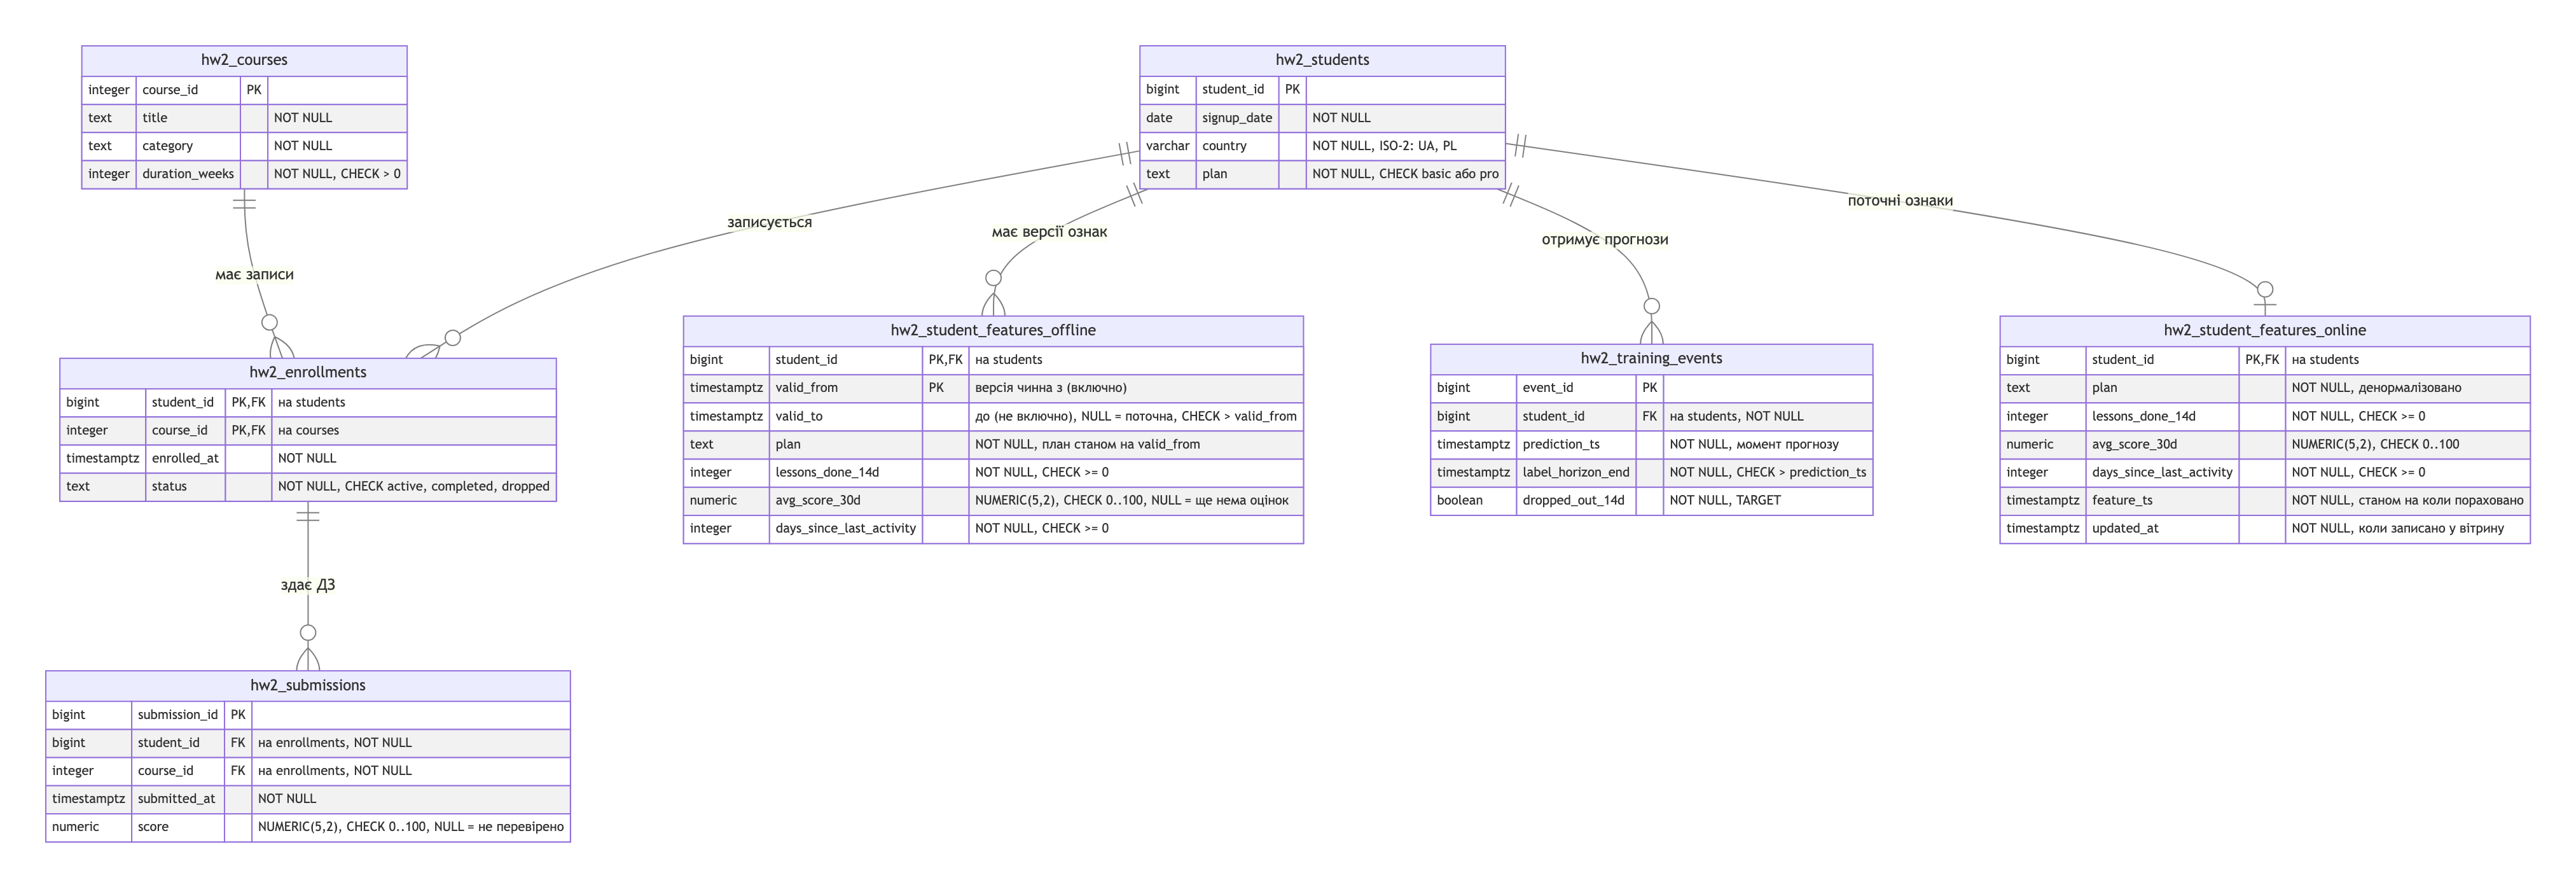

Та сама діаграма текстом (Mermaid, файл `er_diagram.mmd`):

```mermaid
%% ER-діаграма: онлайн-школа, прогноз dropout студента за 14 днів
%% Перегляд і експорт PNG/SVG: https://mermaid.live
erDiagram

    %% ===== Бізнесові сутності =====
    hw2_students    ||--o{ hw2_enrollments : "записується"
    hw2_courses     ||--o{ hw2_enrollments : "має записи"
    hw2_enrollments ||--o{ hw2_submissions : "здає ДЗ"

    hw2_students {
        bigint  student_id  PK
        date    signup_date "NOT NULL"
        varchar country     "NOT NULL, ISO-2: UA, PL"
        text    plan        "NOT NULL, CHECK basic або pro"
    }

    hw2_courses {
        integer course_id      PK
        text    title          "NOT NULL"
        text    category       "NOT NULL"
        integer duration_weeks "NOT NULL, CHECK > 0"
    }

    hw2_enrollments {
        bigint      student_id  PK, FK "на students"
        integer     course_id   PK, FK "на courses"
        timestamptz enrolled_at "NOT NULL"
        text        status      "NOT NULL, CHECK active, completed, dropped"
    }

    hw2_submissions {
        bigint      submission_id PK
        bigint      student_id    FK "на enrollments, NOT NULL"
        integer     course_id     FK "на enrollments, NOT NULL"
        timestamptz submitted_at  "NOT NULL"
        numeric     score         "NUMERIC(5,2), CHECK 0..100, NULL = не перевірено"
    }

    %% ===== Offline feature store (історія, для training) =====
    hw2_students ||--o{ hw2_student_features_offline : "має версії ознак"
    hw2_students ||--o{ hw2_training_events          : "отримує прогнози"

    hw2_student_features_offline {
        bigint      student_id               PK, FK "на students"
        timestamptz valid_from               PK "версія чинна з (включно)"
        timestamptz valid_to                 "до (не включно), NULL = поточна, CHECK > valid_from"
        text        plan                     "NOT NULL, план станом на valid_from"
        integer     lessons_done_14d         "NOT NULL, CHECK >= 0"
        numeric     avg_score_30d            "NUMERIC(5,2), CHECK 0..100, NULL = ще нема оцінок"
        integer     days_since_last_activity "NOT NULL, CHECK >= 0"
    }

    hw2_training_events {
        bigint      event_id          PK
        bigint      student_id        FK "на students, NOT NULL"
        timestamptz prediction_ts     "NOT NULL, момент прогнозу"
        timestamptz label_horizon_end "NOT NULL, CHECK > prediction_ts"
        boolean     dropped_out_14d   "NOT NULL, TARGET"
    }

    %% ===== Online feature store (тільки "зараз", для inference) =====
    hw2_students ||--o| hw2_student_features_online : "поточні ознаки"

    hw2_student_features_online {
        bigint      student_id               PK, FK "на students"
        text        plan                     "NOT NULL, денормалізовано"
        integer     lessons_done_14d         "NOT NULL, CHECK >= 0"
        numeric     avg_score_30d            "NUMERIC(5,2), CHECK 0..100"
        integer     days_since_last_activity "NOT NULL, CHECK >= 0"
        timestamptz feature_ts               "NOT NULL, станом на коли пораховано"
        timestamptz updated_at               "NOT NULL, коли записано у вітрину"
    }
```

## Підготовка: PostgreSQL 16 у Colab

Перша клітинка ставить пакети, друга запускає сервер, третя підключає `%%sql`. Дані лежать у `pgdata` поруч із notebook, поки живе runtime.

In [1]:
!pip install -q "pixeltable-pgserver==0.4.0" jupysql "psycopg[binary]"

In [2]:
import os
import pixeltable_pgserver as pgserver
from sqlalchemy import create_engine

# Postgres 16 всередині Colab; дані лежать у /content/pgdata, поки живе runtime
srv = pgserver.get_server(os.path.abspath("pgdata"), cleanup_mode="stop")
engine = create_engine(srv.get_uri().replace("postgresql://", "postgresql+psycopg://", 1))

/usr/local/lib/python3.13/dist-packages/platformdirs/api.py:459: RuntimeDirWarning: XDG_RUNTIME_DIR is not set, falling back to /tmp/runtime-0
  return Path(self.user_runtime_dir)


In [3]:
%load_ext sql
%config SqlMagic.displaylimit = 50
%sql engine

In [4]:
%%sql
SELECT version();

Running query in 'postgresql+psycopg://postgres:***@/postgres?host=%2Fcontent%2Fpgdata'

1 rows affected.

version
"PostgreSQL 16.10 on x86_64-pc-linux-gnu, compiled by gcc (GCC) 14.2.1 20250110 (Red Hat 14.2.1-7), 64-bit"


## Завдання 2. DDL

Сім таблиць із префіксом `hw2_`. `DROP TABLE IF EXISTS ... CASCADE` на початку дає однаковий результат при кожному повторному запуску. Остання клітинка розділу читає індекси із системного каталогу: для PK і UNIQUE Postgres створює індекс сам, для FK ні, тому індекси на `hw2_enrollments(course_id)` і `hw2_submissions(student_id, course_id)` додані вручну.

In [5]:
%%sql
SET TIME ZONE 'UTC';


DROP TABLE IF EXISTS
    hw2_student_features_online,
    hw2_training_events,
    hw2_student_features_offline,
    hw2_submissions,
    hw2_enrollments,
    hw2_courses,
    hw2_students
CASCADE;


CREATE TABLE hw2_students (
    student_id  BIGINT PRIMARY KEY,
    signup_date DATE NOT NULL,
    country     VARCHAR(2) NOT NULL
        CHECK (country ~ '^[A-Z]{2}$'),
    plan        TEXT NOT NULL
        CHECK (plan IN ('basic', 'pro'))
);

CREATE TABLE hw2_courses (
    course_id      INTEGER PRIMARY KEY,
    title          TEXT NOT NULL,
    category       TEXT NOT NULL,
    duration_weeks INTEGER NOT NULL
        CHECK (duration_weeks > 0)
);

-- Bridge-таблиця students N:M courses
CREATE TABLE hw2_enrollments (
    student_id  BIGINT NOT NULL
        REFERENCES hw2_students(student_id),
    course_id   INTEGER NOT NULL
        REFERENCES hw2_courses(course_id),
    enrolled_at TIMESTAMPTZ NOT NULL,
    status      TEXT NOT NULL
        CHECK (status IN ('active', 'completed', 'dropped')),

    PRIMARY KEY (student_id, course_id)
);

-- PK-індекс починається зі student_id, тому пошук "усі студенти курсу X" він не прискорить
CREATE INDEX hw2_idx_enrollments_course
    ON hw2_enrollments (course_id);

CREATE TABLE hw2_submissions (
    submission_id BIGINT
        GENERATED BY DEFAULT AS IDENTITY
        PRIMARY KEY,
    student_id    BIGINT NOT NULL,
    course_id     INTEGER NOT NULL,
    submitted_at  TIMESTAMPTZ NOT NULL,
    score         NUMERIC(5, 2)
        CHECK (score BETWEEN 0 AND 100),

    -- Складений FK: здати ДЗ можна тільки з курсу, на який студент записаний
    FOREIGN KEY (student_id, course_id)
        REFERENCES hw2_enrollments (student_id, course_id)
);

-- FK-колонки Postgres сам не індексує: без цього DELETE з enrollments сканував би всі submissions
CREATE INDEX hw2_idx_submissions_enrollment
    ON hw2_submissions (student_id, course_id);

Running query in 'postgresql+psycopg://postgres:***@/postgres?host=%2Fcontent%2Fpgdata'

++
||
++
++

In [6]:
%%sql
-- Offline feature store: історія версій ознак

CREATE TABLE hw2_student_features_offline (
    student_id               BIGINT NOT NULL
        REFERENCES hw2_students(student_id),
    plan                     TEXT NOT NULL
        CHECK (plan IN ('basic', 'pro')),
    lessons_done_14d         INTEGER NOT NULL
        CHECK (lessons_done_14d >= 0),
    avg_score_30d            NUMERIC(5, 2)
        CHECK (avg_score_30d BETWEEN 0 AND 100),
    days_since_last_activity INTEGER NOT NULL
        CHECK (days_since_last_activity >= 0),
    valid_from               TIMESTAMPTZ NOT NULL,
    valid_to                 TIMESTAMPTZ,

    PRIMARY KEY (student_id, valid_from),

    CHECK (valid_to IS NULL OR valid_to > valid_from)
);

-- Не більше однієї поточної версії (valid_to IS NULL) на студента.
-- Заодно швидкий пошук поточних версій, коли оновлюємо online-вітрину.
CREATE UNIQUE INDEX hw2_uq_features_offline_current
    ON hw2_student_features_offline (student_id)
    WHERE valid_to IS NULL;

-- Training events: момент прогнозу + правильна відповідь

CREATE TABLE hw2_training_events (
    event_id          BIGINT
        GENERATED BY DEFAULT AS IDENTITY
        PRIMARY KEY,
    student_id        BIGINT NOT NULL
        REFERENCES hw2_students(student_id),
    prediction_ts     TIMESTAMPTZ NOT NULL,
    label_horizon_end TIMESTAMPTZ NOT NULL,
    dropped_out_14d   BOOLEAN NOT NULL,

    UNIQUE (student_id, prediction_ts),
    CHECK (label_horizon_end > prediction_ts)
);

-- Online feature store: 1 рядок на студента, тільки "зараз"

CREATE TABLE hw2_student_features_online (
    student_id               BIGINT PRIMARY KEY
        REFERENCES hw2_students(student_id),
    plan                     TEXT NOT NULL
        CHECK (plan IN ('basic', 'pro')),
    lessons_done_14d         INTEGER NOT NULL
        CHECK (lessons_done_14d >= 0),
    avg_score_30d            NUMERIC(5, 2)
        CHECK (avg_score_30d BETWEEN 0 AND 100),
    days_since_last_activity INTEGER NOT NULL
        CHECK (days_since_last_activity >= 0),
    feature_ts               TIMESTAMPTZ NOT NULL,
    updated_at               TIMESTAMPTZ NOT NULL
        DEFAULT CURRENT_TIMESTAMP
);

Running query in 'postgresql+psycopg://postgres:***@/postgres?host=%2Fcontent%2Fpgdata'

++
||
++
++

In [7]:
%%sql
SELECT tablename, indexname, indexdef
FROM pg_indexes
WHERE tablename LIKE 'hw2_%'
ORDER BY tablename, indexname;

Running query in 'postgresql+psycopg://postgres:***@/postgres?host=%2Fcontent%2Fpgdata'

11 rows affected.

tablename,indexname,indexdef
hw2_courses,hw2_courses_pkey,CREATE UNIQUE INDEX hw2_courses_pkey ON public.hw2_courses USING btree (course_id)
hw2_enrollments,hw2_enrollments_pkey,"CREATE UNIQUE INDEX hw2_enrollments_pkey ON public.hw2_enrollments USING btree (student_id, course_id)"
hw2_enrollments,hw2_idx_enrollments_course,CREATE INDEX hw2_idx_enrollments_course ON public.hw2_enrollments USING btree (course_id)
hw2_student_features_offline,hw2_student_features_offline_pkey,"CREATE UNIQUE INDEX hw2_student_features_offline_pkey ON public.hw2_student_features_offline USING btree (student_id, valid_from)"
hw2_student_features_offline,hw2_uq_features_offline_current,CREATE UNIQUE INDEX hw2_uq_features_offline_current ON public.hw2_student_features_offline USING btree (student_id) WHERE (valid_to IS NULL)
hw2_student_features_online,hw2_student_features_online_pkey,CREATE UNIQUE INDEX hw2_student_features_online_pkey ON public.hw2_student_features_online USING btree (student_id)
hw2_students,hw2_students_pkey,CREATE UNIQUE INDEX hw2_students_pkey ON public.hw2_students USING btree (student_id)
hw2_submissions,hw2_idx_submissions_enrollment,"CREATE INDEX hw2_idx_submissions_enrollment ON public.hw2_submissions USING btree (student_id, course_id)"
hw2_submissions,hw2_submissions_pkey,CREATE UNIQUE INDEX hw2_submissions_pkey ON public.hw2_submissions USING btree (submission_id)
hw2_training_events,hw2_training_events_pkey,CREATE UNIQUE INDEX hw2_training_events_pkey ON public.hw2_training_events USING btree (event_id)


**Бізнесові дані**

In [8]:
%%sql

INSERT INTO hw2_students (student_id, signup_date, country, plan) VALUES
    (1, DATE '2024-09-01', 'UA', 'basic'),
    (2, DATE '2024-09-15', 'PL', 'pro'),   -- зараз pro, але до 1 грудня був basic
    (3, DATE '2024-10-01', 'UA', 'basic'),
    (4, DATE '2024-11-20', 'DE', 'basic'); -- новенький: ще без курсів і без ознак

INSERT INTO hw2_courses (course_id, title, category, duration_weeks) VALUES
    (10, 'SQL для ML',       'data',        8),
    (20, 'Python Core',      'programming', 12),
    (30, 'Machine Learning', 'data',        16);

-- N:M: у студента 1 два курси, на курсі 10 два студенти
INSERT INTO hw2_enrollments (student_id, course_id, enrolled_at, status) VALUES
    (1, 10, TIMESTAMPTZ '2024-09-02 09:00:00+00', 'active'),
    (1, 20, TIMESTAMPTZ '2024-09-05 12:00:00+00', 'completed'),
    (2, 10, TIMESTAMPTZ '2024-09-16 08:30:00+00', 'active'),
    (2, 30, TIMESTAMPTZ '2024-10-01 10:00:00+00', 'active'),
    (3, 20, TIMESTAMPTZ '2024-10-02 18:00:00+00', 'dropped');

INSERT INTO hw2_submissions (student_id, course_id, submitted_at, score) VALUES
    (1, 10, TIMESTAMPTZ '2024-10-10 20:00:00+00', 85.50),
    (1, 10, TIMESTAMPTZ '2024-11-05 21:15:00+00', 92.00),
    (2, 30, TIMESTAMPTZ '2024-11-12 19:40:00+00', 74.25),
    (2, 10, TIMESTAMPTZ '2024-12-01 10:00:00+00', NULL),  -- ще не перевірено
    (2, 30, TIMESTAMPTZ '2024-12-20 18:00:00+00', 81.00),
    (3, 20, TIMESTAMPTZ '2024-10-20 17:00:00+00', 61.00);

-- Offline feature store: 11 версій для 3 студентів
-- Кожна версія живе на [valid_from, valid_to); наступна починається рівно там, де закінчилась попередня

INSERT INTO hw2_student_features_offline
    (student_id, plan, lessons_done_14d, avg_score_30d, days_since_last_activity, valid_from, valid_to)
VALUES
    -- студент 1: активний, потім затихає (4 версії)
    (1, 'basic', 9, 85.50,  1, TIMESTAMPTZ '2024-11-01 00:00:00+00', TIMESTAMPTZ '2024-11-15 00:00:00+00'),
    (1, 'basic', 6, 92.00,  2, TIMESTAMPTZ '2024-11-15 00:00:00+00', TIMESTAMPTZ '2024-12-01 00:00:00+00'),
    (1, 'basic', 2, 92.00,  6, TIMESTAMPTZ '2024-12-01 00:00:00+00', TIMESTAMPTZ '2024-12-15 00:00:00+00'),
    (1, 'basic', 0, NULL,  20, TIMESTAMPTZ '2024-12-15 00:00:00+00', NULL),

    -- студент 2: стабільний, 1 грудня перейшов з basic на pro (4 версії)
    (2, 'basic', 5,  NULL,  3, TIMESTAMPTZ '2024-11-01 00:00:00+00', TIMESTAMPTZ '2024-11-15 00:00:00+00'),
    (2, 'basic', 6,  74.25, 2, TIMESTAMPTZ '2024-11-15 00:00:00+00', TIMESTAMPTZ '2024-12-01 00:00:00+00'),
    (2, 'pro',   8,  74.25, 1, TIMESTAMPTZ '2024-12-01 00:00:00+00', TIMESTAMPTZ '2025-01-01 00:00:00+00'),
    (2, 'pro',  10,  81.00, 0, TIMESTAMPTZ '2025-01-01 00:00:00+00', NULL),

    -- студент 3: кинув Python Core, активність згасає (3 версії)
    (3, 'basic', 3, 61.00,  4, TIMESTAMPTZ '2024-11-01 00:00:00+00', TIMESTAMPTZ '2024-11-20 00:00:00+00'),
    (3, 'basic', 0, NULL,  12, TIMESTAMPTZ '2024-11-20 00:00:00+00', TIMESTAMPTZ '2024-12-10 00:00:00+00'),
    (3, 'basic', 0, NULL,  32, TIMESTAMPTZ '2024-12-10 00:00:00+00', NULL);

-- Training events: "у момент prediction_ts треба було спрогнозувати" + правильна відповідь

INSERT INTO hw2_training_events (student_id, prediction_ts, label_horizon_end, dropped_out_14d) VALUES
    (1, TIMESTAMPTZ '2024-11-10 10:00:00+00', TIMESTAMPTZ '2024-11-24 10:00:00+00', FALSE),
    (1, TIMESTAMPTZ '2024-12-05 10:00:00+00', TIMESTAMPTZ '2024-12-19 10:00:00+00', TRUE),
    (1, TIMESTAMPTZ '2024-12-15 00:00:00+00', TIMESTAMPTZ '2024-12-29 00:00:00+00', TRUE),  -- рівно на межі версій
    (2, TIMESTAMPTZ '2024-11-20 10:00:00+00', TIMESTAMPTZ '2024-12-04 10:00:00+00', FALSE), -- тоді ще basic
    (2, TIMESTAMPTZ '2025-01-05 10:00:00+00', TIMESTAMPTZ '2025-01-19 10:00:00+00', FALSE),
    (3, TIMESTAMPTZ '2024-11-05 10:00:00+00', TIMESTAMPTZ '2024-11-19 10:00:00+00', FALSE),
    (3, TIMESTAMPTZ '2024-11-25 10:00:00+00', TIMESTAMPTZ '2024-12-09 10:00:00+00', TRUE),
    (4, TIMESTAMPTZ '2024-12-01 10:00:00+00', TIMESTAMPTZ '2024-12-15 10:00:00+00', FALSE); -- ознак ще нема

Running query in 'postgresql+psycopg://postgres:***@/postgres?host=%2Fcontent%2Fpgdata'

4 rows affected.

3 rows affected.

5 rows affected.

6 rows affected.

11 rows affected.

8 rows affected.

++
||
++
++

Перевірка кількостей

In [9]:
%%sql
SELECT 'students' AS table_name, COUNT(*) AS rows FROM hw2_students
UNION ALL SELECT 'courses',           COUNT(*) FROM hw2_courses
UNION ALL SELECT 'enrollments',       COUNT(*) FROM hw2_enrollments
UNION ALL SELECT 'submissions',       COUNT(*) FROM hw2_submissions
UNION ALL SELECT 'features_offline',  COUNT(*) FROM hw2_student_features_offline
UNION ALL SELECT 'training_events',   COUNT(*) FROM hw2_training_events;

Running query in 'postgresql+psycopg://postgres:***@/postgres?host=%2Fcontent%2Fpgdata'

6 rows affected.

table_name,rows
students,4
courses,3
enrollments,5
submissions,6
features_offline,11
training_events,8


### Перевірка обмежень

Хелпер `try_sql` виконує запит і завжди відкочує транзакцію, тому таблиці не змінюються. Шість спроб із восьми зупиняють constraints. Дві проходять. CHECK пропускає NULL, бо `NULL BETWEEN 0 AND 100` дає UNKNOWN, а відкидаються лише рядки з FALSE. Перекриття інтервалів CHECK не бачить, бо перевіряє один рядок, тому для нього є окремий запит у Завданні 4.

In [10]:
from sqlalchemy import text
from sqlalchemy.exc import DBAPIError

def try_sql(label, sql):
    """Пробує виконати SQL і завжди відкочує транзакцію. Дані в таблицях не змінюються."""
    with engine.connect() as conn:
        tx = conn.begin()
        try:
            conn.execute(text(sql))
            print(f"{label} → ПРОЙШЛО")
        except DBAPIError as e:
            print(f"{label} → НЕ ПРОЙШЛО {str(e.orig).splitlines()[0]}")
        finally:
            tx.rollback()

In [11]:
try_sql("1. План 'vip'",
        "INSERT INTO hw2_students VALUES (5, DATE '2024-12-01', 'UA', 'vip')")

try_sql("2. Запис на курс неіснуючого студента 999",
        "INSERT INTO hw2_enrollments VALUES (999, 10, TIMESTAMPTZ '2024-12-01 10:00:00+00', 'active')")

try_sql("3. Студент 3 здає ДЗ з курсу 10, на який не записаний",
        "INSERT INTO hw2_submissions (student_id, course_id, submitted_at, score) "
        "VALUES (3, 10, TIMESTAMPTZ '2024-12-01 10:00:00+00', 90)")

try_sql("4. Видалити студента 1, у якого є записи й історія",
        "DELETE FROM hw2_students WHERE student_id = 1")

try_sql("5. Версія, що закінчується раніше, ніж почалась",
        "INSERT INTO hw2_student_features_offline VALUES "
        "(3, 'basic', 1, 50, 1, TIMESTAMPTZ '2025-02-01 00:00:00+00', TIMESTAMPTZ '2025-01-01 00:00:00+00')")

try_sql("6. Друга поточна версія (valid_to NULL) для студента 1",
        "INSERT INTO hw2_student_features_offline VALUES "
        "(1, 'basic', 1, 50, 1, TIMESTAMPTZ '2025-01-01 00:00:00+00', NULL)")

try_sql("7. Домашка з оцінкою NULL",
        "INSERT INTO hw2_submissions (student_id, course_id, submitted_at, score) "
        "VALUES (1, 10, TIMESTAMPTZ '2024-12-01 10:00:00+00', NULL)")

try_sql("8. Версія 10–25 листопада для студента 3, що наїжджає на дві інші",
        "INSERT INTO hw2_student_features_offline VALUES "
        "(3, 'basic', 1, 50, 1, TIMESTAMPTZ '2024-11-10 00:00:00+00', TIMESTAMPTZ '2024-11-25 00:00:00+00')")

1. План 'vip' → НЕ ПРОЙШЛО new row for relation "hw2_students" violates check constraint "hw2_students_plan_check"
2. Запис на курс неіснуючого студента 999 → НЕ ПРОЙШЛО insert or update on table "hw2_enrollments" violates foreign key constraint "hw2_enrollments_student_id_fkey"
3. Студент 3 здає ДЗ з курсу 10, на який не записаний → НЕ ПРОЙШЛО insert or update on table "hw2_submissions" violates foreign key constraint "hw2_submissions_student_id_course_id_fkey"
4. Видалити студента 1, у якого є записи й історія → НЕ ПРОЙШЛО update or delete on table "hw2_students" violates foreign key constraint "hw2_enrollments_student_id_fkey" on table "hw2_enrollments"
5. Версія, що закінчується раніше, ніж почалась → НЕ ПРОЙШЛО new row for relation "hw2_student_features_offline" violates check constraint "hw2_student_features_offline_check"
6. Друга поточна версія (valid_to NULL) для студента 1 → НЕ ПРОЙШЛО duplicate key value violates unique constraint "hw2_uq_features_offline_current"
7. Домашка

### Оновлення online-вітрини і нові версії ознак

`refresh_online()` робить UPSERT поточних версій з offline-таблиці у вітрину. Другий запуск поспіль нічого не змінює, бо рядок оновлюється лише тоді, коли прийшла новіша версія. `add_feature_version()` закриває поточну версію і відкриває нову в одній транзакції (SCD Type 2). Якщо другий крок падає, Postgres відкочує і перший: остання версія студента 3 лишається відкритою.

In [12]:
REFRESH_ONLINE_SQL = text("""
    INSERT INTO hw2_student_features_online
        (student_id, plan, lessons_done_14d, avg_score_30d,
         days_since_last_activity, feature_ts, updated_at)
    SELECT student_id, plan, lessons_done_14d, avg_score_30d,
           days_since_last_activity, valid_from, CURRENT_TIMESTAMP
    FROM hw2_student_features_offline
    WHERE valid_to IS NULL                      -- тільки поточні версії
    ON CONFLICT (student_id) DO UPDATE          -- студент уже є у вітрині → оновлюємо
    SET plan                     = EXCLUDED.plan,
        lessons_done_14d         = EXCLUDED.lessons_done_14d,
        avg_score_30d            = EXCLUDED.avg_score_30d,
        days_since_last_activity = EXCLUDED.days_since_last_activity,
        feature_ts               = EXCLUDED.feature_ts,
        updated_at               = EXCLUDED.updated_at
    WHERE hw2_student_features_online.feature_ts < EXCLUDED.feature_ts  -- лише якщо прийшло новіше
""")

def refresh_online():
    """Переносить поточні версії з offline у вітрину; чіпає лише ті рядки, що змінились."""
    with engine.begin() as conn:
        n = conn.execute(REFRESH_ONLINE_SQL).rowcount
    print(f"Вітрина: вставлено або оновлено {n} рядків")

refresh_online()
refresh_online()

Вітрина: вставлено або оновлено 3 рядків
Вітрина: вставлено або оновлено 0 рядків


In [13]:
%%sql
SELECT student_id, plan, lessons_done_14d, avg_score_30d, days_since_last_activity, feature_ts
FROM hw2_student_features_online
ORDER BY student_id;

Running query in 'postgresql+psycopg://postgres:***@/postgres?host=%2Fcontent%2Fpgdata'

3 rows affected.

student_id,plan,lessons_done_14d,avg_score_30d,days_since_last_activity,feature_ts
1,basic,0,None,20,2024-12-15 00:00:00+00:00
2,pro,10,81.00,0,2025-01-01 00:00:00+00:00
3,basic,0,None,32,2024-12-10 00:00:00+00:00


In [14]:
from datetime import datetime, timezone

CLOSE_CURRENT_SQL = text("""
    UPDATE hw2_student_features_offline
    SET valid_to = :valid_from
    WHERE student_id = :student_id
      AND valid_to IS NULL
""")

INSERT_VERSION_SQL = text("""
    INSERT INTO hw2_student_features_offline
        (student_id, plan, lessons_done_14d, avg_score_30d,
         days_since_last_activity, valid_from, valid_to)
    VALUES
        (:student_id, :plan, :lessons_done_14d, :avg_score_30d,
         :days_since_last_activity, :valid_from, NULL)
""")

def add_feature_version(**version):
    """SCD Type 2: закрити поточну версію і відкрити нову атомарно, в одній транзакції."""
    with engine.begin() as conn:  # BEGIN ... COMMIT, а при будь-якій помилці ROLLBACK
        conn.execute(CLOSE_CURRENT_SQL, version)
        conn.execute(INSERT_VERSION_SQL, version)

# Студент 3 повернувся до навчання 10 січня
add_feature_version(
    student_id=3, plan="basic", lessons_done_14d=4, avg_score_30d=70.00,
    days_since_last_activity=0, valid_from=datetime(2025, 1, 10, tzinfo=timezone.utc),
)
print("Нова версія додана")

Нова версія додана


In [15]:
# Крок 1 (UPDATE) пройде і закриє поточну версію, а крок 2 (INSERT) впаде на plan = 'vip'
try:
    add_feature_version(
        student_id=3, plan="vip", lessons_done_14d=5, avg_score_30d=75.00,
        days_since_last_activity=1, valid_from=datetime(2025, 2, 1, tzinfo=timezone.utc),
    )
except DBAPIError as e:
    print("Відкат усієї транзакції:", str(e.orig).splitlines()[0])

Відкат усієї транзакції: new row for relation "hw2_student_features_offline" violates check constraint "hw2_student_features_offline_plan_check"


In [16]:
%%sql
SELECT student_id, lessons_done_14d, avg_score_30d, valid_from, valid_to
FROM hw2_student_features_offline
WHERE student_id = 3
ORDER BY valid_from;

Running query in 'postgresql+psycopg://postgres:***@/postgres?host=%2Fcontent%2Fpgdata'

4 rows affected.

student_id,lessons_done_14d,avg_score_30d,valid_from,valid_to
3,3,61.00,2024-11-01 00:00:00+00:00,2024-11-20 00:00:00+00:00
3,0,None,2024-11-20 00:00:00+00:00,2024-12-10 00:00:00+00:00
3,0,None,2024-12-10 00:00:00+00:00,2025-01-10 00:00:00+00:00
3,4,70.00,2025-01-10 00:00:00+00:00,None


In [17]:
refresh_online()

Вітрина: вставлено або оновлено 1 рядків


## Завдання 3. Нормалізація

Бізнесові таблиці `hw2_students`, `hw2_courses`, `hw2_enrollments`, `hw2_submissions` і `hw2_training_events` у 3НФ. У кожній неключові колонки залежать від усього ключа і більше ні від чого.

Функціональні залежності, з яких я виходив:

- `student_id → signup_date, country, plan`
- `course_id → title, category, duration_weeks`
- `(student_id, course_id) → enrolled_at, status`
- `submission_id → student_id, course_id, submitted_at, score`
- `event_id → student_id, prediction_ts, label_horizon_end, dropped_out_14d`

Назву курсу в `hw2_submissions` я не зберігаю. Це була б транзитивна залежність `submission_id → course_id → title`, і після перейменування курсу довелося б оновлювати кожну здану домашку. Зв'язок студентів і курсів N:M, тому він живе в окремій таблиці `hw2_enrollments`.

`hw2_student_features_offline` теж у 3НФ з ключем `(student_id, valid_from)`. Колонка `plan` тут не дублює `hw2_students.plan`: у студентів лежить тариф зараз, а в архіві тариф на момент `valid_from`. Для навчання потрібен саме другий.

Навмисно денормалізована `hw2_student_features_online`: один рядок на студента, де поруч лежать тариф і всі ознаки. Inference питає ознаки одного студента, і цей запит закривається одним пошуком за первинним ключем, без JOIN з `hw2_students` і без пошуку потрібної версії в історії. Тому відповідь швидка.

За це платимо дублюванням. Між оновленнями вітрина відстає від архіву, а тариф у вітрині може розійтися з `hw2_students`, якщо студент змінив його до наступного перерахунку ознак. Вітрину оновлює `refresh_online()`: UPSERT поточних версій (`valid_to IS NULL`) з offline-таблиці, причому рядок змінюється лише тоді, коли прийшла новіша версія. Функцію запускають після кожного перерахунку ознак, а відставання видно з `now() - feature_ts`.

## Завдання 4. Point-in-Time correctness

В історії ознак 12 версій: по 4 у студентів 1, 2 і 3. Студент 4 ознак не має. Нижче чотири AS-OF SELECT, AS-OF JOIN для навчальної вибірки, діагностика наївного JOIN і перевірка перекриттів, яка має повернути 0 рядків.

In [18]:
%%sql
-- AS-OF #1: які ознаки мав студент 1 на момент 2024-12-05 10:00 UTC?
SELECT student_id, plan, lessons_done_14d, avg_score_30d, days_since_last_activity,
       valid_from, valid_to
FROM hw2_student_features_offline
WHERE student_id = 1
  AND valid_from <= TIMESTAMPTZ '2024-12-05 10:00:00+00'
  AND (valid_to >  TIMESTAMPTZ '2024-12-05 10:00:00+00' OR valid_to IS NULL);

Running query in 'postgresql+psycopg://postgres:***@/postgres?host=%2Fcontent%2Fpgdata'

1 rows affected.

student_id,plan,lessons_done_14d,avg_score_30d,days_since_last_activity,valid_from,valid_to
1,basic,2,92.00,6,2024-12-01 00:00:00+00:00,2024-12-15 00:00:00+00:00


In [19]:
%%sql
-- AS-OF #2: момент рівно на межі версій. [valid_from, valid_to) → має бути ОДНА версія, нова
SELECT student_id, lessons_done_14d, avg_score_30d, valid_from, valid_to
FROM hw2_student_features_offline
WHERE student_id = 1
  AND valid_from <= TIMESTAMPTZ '2024-12-15 00:00:00+00'
  AND (valid_to >  TIMESTAMPTZ '2024-12-15 00:00:00+00' OR valid_to IS NULL);

Running query in 'postgresql+psycopg://postgres:***@/postgres?host=%2Fcontent%2Fpgdata'

1 rows affected.

student_id,lessons_done_14d,avg_score_30d,valid_from,valid_to
1,0,None,2024-12-15 00:00:00+00:00,None


In [20]:
%%sql
-- AS-OF #3: знімок усього feature store станом на 2024-12-01 00:00 UTC (по рядку на студента)
SELECT student_id, plan, lessons_done_14d, avg_score_30d, days_since_last_activity,
       valid_from, valid_to
FROM hw2_student_features_offline
WHERE valid_from <= TIMESTAMPTZ '2024-12-01 00:00:00+00'
  AND (valid_to >  TIMESTAMPTZ '2024-12-01 00:00:00+00' OR valid_to IS NULL)
ORDER BY student_id;

Running query in 'postgresql+psycopg://postgres:***@/postgres?host=%2Fcontent%2Fpgdata'

3 rows affected.

student_id,plan,lessons_done_14d,avg_score_30d,days_since_last_activity,valid_from,valid_to
1,basic,2,92.00,6,2024-12-01 00:00:00+00:00,2024-12-15 00:00:00+00:00
2,pro,8,74.25,1,2024-12-01 00:00:00+00:00,2025-01-01 00:00:00+00:00
3,basic,0,None,12,2024-11-20 00:00:00+00:00,2024-12-10 00:00:00+00:00


In [21]:
%%sql
-- AS-OF #4: leakage через звичайну таблицю. План студента 2 "зараз" проти плану на 2024-11-20
SELECT s.student_id,
       s.plan AS plan_now_in_students,
       f.plan AS plan_as_of_2024_11_20
FROM hw2_students AS s
JOIN hw2_student_features_offline AS f
  ON f.student_id = s.student_id
 AND f.valid_from <= TIMESTAMPTZ '2024-11-20 10:00:00+00'
 AND (f.valid_to >  TIMESTAMPTZ '2024-11-20 10:00:00+00' OR f.valid_to IS NULL)
WHERE s.student_id = 2;

Running query in 'postgresql+psycopg://postgres:***@/postgres?host=%2Fcontent%2Fpgdata'

1 rows affected.

student_id,plan_now_in_students,plan_as_of_2024_11_20
2,pro,basic


In [22]:
%%sql
-- AS-OF JOIN: навчальна вибірка. Кожен білет + ознаки, чинні на його prediction_ts
SELECT e.event_id,
       e.student_id,
       e.prediction_ts,
       f.plan,
       f.lessons_done_14d,
       f.avg_score_30d,
       f.days_since_last_activity,
       e.dropped_out_14d AS target
FROM hw2_training_events AS e
LEFT JOIN hw2_student_features_offline AS f
       ON f.student_id = e.student_id
      AND f.valid_from <= e.prediction_ts
      AND (f.valid_to > e.prediction_ts OR f.valid_to IS NULL)
ORDER BY e.event_id;

Running query in 'postgresql+psycopg://postgres:***@/postgres?host=%2Fcontent%2Fpgdata'

8 rows affected.

event_id,student_id,prediction_ts,plan,lessons_done_14d,avg_score_30d,days_since_last_activity,target
1,1,2024-11-10 10:00:00+00:00,basic,9,85.50,1,False
2,1,2024-12-05 10:00:00+00:00,basic,2,92.00,6,True
3,1,2024-12-15 00:00:00+00:00,basic,0,None,20,True
4,2,2024-11-20 10:00:00+00:00,basic,6,74.25,2,False
5,2,2025-01-05 10:00:00+00:00,pro,10,81.00,0,False
6,3,2024-11-05 10:00:00+00:00,basic,3,61.00,4,False
7,3,2024-11-25 10:00:00+00:00,basic,0,None,12,True
8,4,2024-12-01 10:00:00+00:00,None,None,None,None,False


In [23]:
%%sql
-- Діагностика НЕПРАВИЛЬНОГО JOIN лише за student_id: скільки версій прилипло до кожного білета
SELECT e.event_id,
       e.student_id,
       e.prediction_ts,
       COUNT(f.student_id)                                    AS joined_versions,
       COUNT(f.student_id) FILTER (WHERE f.valid_from > e.prediction_ts) AS from_future
FROM hw2_training_events AS e
LEFT JOIN hw2_student_features_offline AS f
       ON f.student_id = e.student_id
GROUP BY e.event_id, e.student_id, e.prediction_ts
ORDER BY e.event_id;

Running query in 'postgresql+psycopg://postgres:***@/postgres?host=%2Fcontent%2Fpgdata'

8 rows affected.

event_id,student_id,prediction_ts,joined_versions,from_future
1,1,2024-11-10 10:00:00+00:00,4,3
2,1,2024-12-05 10:00:00+00:00,4,1
3,1,2024-12-15 00:00:00+00:00,4,0
4,2,2024-11-20 10:00:00+00:00,4,2
5,2,2025-01-05 10:00:00+00:00,4,0
6,3,2024-11-05 10:00:00+00:00,4,3
7,3,2024-11-25 10:00:00+00:00,4,2
8,4,2024-12-01 10:00:00+00:00,0,0


In [24]:
%%sql
-- Порівняння розмірів: правильний AS-OF JOIN проти наївного JOIN
SELECT
    (SELECT COUNT(*) FROM hw2_training_events)                       AS events,
    (SELECT COUNT(*)
       FROM hw2_training_events e
       LEFT JOIN hw2_student_features_offline f
              ON f.student_id = e.student_id
             AND f.valid_from <= e.prediction_ts
             AND (f.valid_to > e.prediction_ts OR f.valid_to IS NULL)) AS asof_join_rows,
    (SELECT COUNT(*)
       FROM hw2_training_events e
       JOIN hw2_student_features_offline f
         ON f.student_id = e.student_id)                              AS naive_join_rows;

Running query in 'postgresql+psycopg://postgres:***@/postgres?host=%2Fcontent%2Fpgdata'

1 rows affected.

events,asof_join_rows,naive_join_rows
8,8,28


In [25]:
%%sql
-- Має повернути 0 рядків: у жодного студента версії не перекриваються
SELECT a.student_id, a.valid_from AS a_from, a.valid_to AS a_to, b.valid_from AS b_from, b.valid_to AS b_to
FROM hw2_student_features_offline AS a
JOIN hw2_student_features_offline AS b
  ON a.student_id = b.student_id
 AND a.valid_from < COALESCE(b.valid_to, 'infinity'::timestamptz)
 AND b.valid_from < COALESCE(a.valid_to, 'infinity'::timestamptz)
 AND a.valid_from < b.valid_from;

Running query in 'postgresql+psycopg://postgres:***@/postgres?host=%2Fcontent%2Fpgdata'

student_id,a_from,a_to,b_from,b_to


In [26]:
%%sql
-- Бонус: той самий AS-OF через LATERAL. "Остання версія, що почалась не пізніше prediction_ts"
SELECT e.event_id, e.student_id, e.prediction_ts,
       f.lessons_done_14d, f.avg_score_30d, f.valid_from
FROM hw2_training_events AS e
LEFT JOIN LATERAL (
    SELECT *
    FROM hw2_student_features_offline AS f
    WHERE f.student_id = e.student_id
      AND f.valid_from <= e.prediction_ts
      AND (f.valid_to > e.prediction_ts OR f.valid_to IS NULL)
    ORDER BY f.valid_from DESC
    LIMIT 1
) AS f ON TRUE
ORDER BY e.event_id;

Running query in 'postgresql+psycopg://postgres:***@/postgres?host=%2Fcontent%2Fpgdata'

8 rows affected.

event_id,student_id,prediction_ts,lessons_done_14d,avg_score_30d,valid_from
1,1,2024-11-10 10:00:00+00:00,9,85.50,2024-11-01 00:00:00+00:00
2,1,2024-12-05 10:00:00+00:00,2,92.00,2024-12-01 00:00:00+00:00
3,1,2024-12-15 00:00:00+00:00,0,None,2024-12-15 00:00:00+00:00
4,2,2024-11-20 10:00:00+00:00,6,74.25,2024-11-15 00:00:00+00:00
5,2,2025-01-05 10:00:00+00:00,10,81.00,2025-01-01 00:00:00+00:00
6,3,2024-11-05 10:00:00+00:00,3,61.00,2024-11-01 00:00:00+00:00
7,3,2024-11-25 10:00:00+00:00,0,None,2024-11-20 00:00:00+00:00
8,4,2024-12-01 10:00:00+00:00,None,None,None


### Пояснення до AS-OF запитів

`valid_from <= prediction_ts` залишає тільки версії, які вже існували в момент прогнозу. Версія, що почалась пізніше, для цього моменту є майбутнім, і в проді модель її не побачила б.

`valid_to > prediction_ts OR valid_to IS NULL` означає, що на цей момент версія ще не закінчилась. Без `OR valid_to IS NULL` випали б усі поточні версії: у них `valid_to` порожній, порівняння з NULL дає UNKNOWN, і рядок не проходить фільтр.

Інтервал напіввідкритий, `[valid_from, valid_to)`, бо сусідні версії стикуються: `valid_to` старої дорівнює `valid_from` нової. Якби обидві межі входили в інтервал, момент стику належав би двом версіям, і подія отримала б дубль. Так кожен момент належить рівно одній версії. Подія 3 з `prediction_ts = 2024-12-15 00:00` отримала нову версію з 0 уроків, а не стару.

Без часового фільтра (`JOIN ... ON f.student_id = e.student_id`) вийшло 28 рядків замість 8. Кожна подія розмножилась на всі версії свого студента, і 11 із цих рядків узяті з майбутнього. Подія 1 (10 листопада, у студента 9 уроків за 14 днів) отримала б і версію з 15 грудня, де уроків 0. Модель навчилась би на тому, що студент згодом затихне, хоча 10 листопада цього ще ніхто не знав. Одна подія з'являлась би кілька разів з різними ознаками й однаковим target, а метрики на валідації виглядали б кращими, ніж модель покаже в проді. Подія 8 (студент 4 без ознак) при звичайному JOIN зникла б зовсім, тому в робочому запиті стоїть LEFT JOIN.

Майбутнє може протекти і зі звичайної бізнес-таблиці. У `hw2_students` для студента 2 зараз записано `pro`, а 20 листопада він ще був на `basic` (запит AS-OF #4). Тому тариф для навчання береться з історії ознак.

## Завдання 5. Reflection

Найскладнішим для мене виявились не сутності. Домен онлайн-школи знайомий, і студенти, курси та записи на курси склались одразу. Застряг я на кардинальностях feature-таблиць: не розумів, як рахувати зв'язок студента з архівом і з вітриною, поки не пов'язав це з первинним ключем. PK `(student_id, valid_from)` дозволяє багато версій, тому це 1:N, а PK `student_id` у вітрині дає не більше одного рядка, тобто 1:0..1. Окремо довелося розібратися, що таке індекс і B-tree і чому Postgres не індексує FK сам. У point-in-time найбільше здивувало, що база спокійно приймає версію, яка перекривається з іншими. CHECK бачить лише один рядок, тому перекриття ловить тільки окремий запит.

Бізнесову частину я нормалізував до 3НФ, а `plan` зберігаю ще й в історії ознак, бо `hw2_students` знає тільки поточний тариф. Вітрина денормалізована під lookup за `student_id`. Індекс із шаблону `(id, valid_from DESC)` я не дублював, бо PK уже створює B-tree на тих самих колонках. Натомість частковий унікальний індекс `WHERE valid_to IS NULL` дозволяє лише одну поточну версію на студента. `EXCLUDE` для інтервалів не вийшло, бо в pgserver немає `btree_gist`.

Для дуже швидкого lookup на великій кількості користувачів я б лишив один готовий рядок на студента, але рахував би ознаки заздалегідь батчем і тримав їх у key-value сховищі або кеші перед Postgres. Дані можна шардувати за `student_id`, а читання розносити по репліках. Свіжість перевіряв би через `now() - feature_ts` з алертом на поріг.

За пів року схема точно зміниться. Перейменування ознаки ламає всіх читачів, тому безпечніше додати нову колонку і прибрати стару, коли її ніхто не читає. Якщо змінюється тип чи вікно (скажімо, `lessons_done_14d` переходить на 7 днів), це нова ознака з новою назвою, а не тиха зміна старої. Старі моделі далі читатимуть старі ознаки, тож їх і історію треба тримати, доки ці моделі в проді, а зміни проводити міграціями з review.